# Explainable bike demand with SHAP

Run `uv run python -m bike_demand.train` first. Data: UCI Bike Sharing, hourly, Washington D.C. 2011–2012.

In [1]:
import json

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

from bike_demand.data import FEATURES, MODEL, ROOT, TARGET, load, split

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight"})
SEASONS = {1: "winter", 2: "spring", 3: "summer", 4: "fall"}

df = load()
train, valid, test = split(df)
model = lgb.Booster(model_file=str(MODEL))
X, Xt, yt = df[FEATURES], test[FEATURES], test[TARGET].to_numpy()
json.loads((MODEL.parent / "metrics.json").read_text())

/Users/p.schmidt-petter/Desktop/dev/dev/explainable-bike-demand/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'best_iteration': 727,
 'test_period': '2012-10-01..2012-12-31',
 'lightgbm': {'rmse': 62.6, 'mae': 39.43, 'r2': 0.9036},
 'baseline_hour_x_workingday': {'rmse': 119.59, 'mae': 79.95, 'r2': 0.6481}}

## EDA

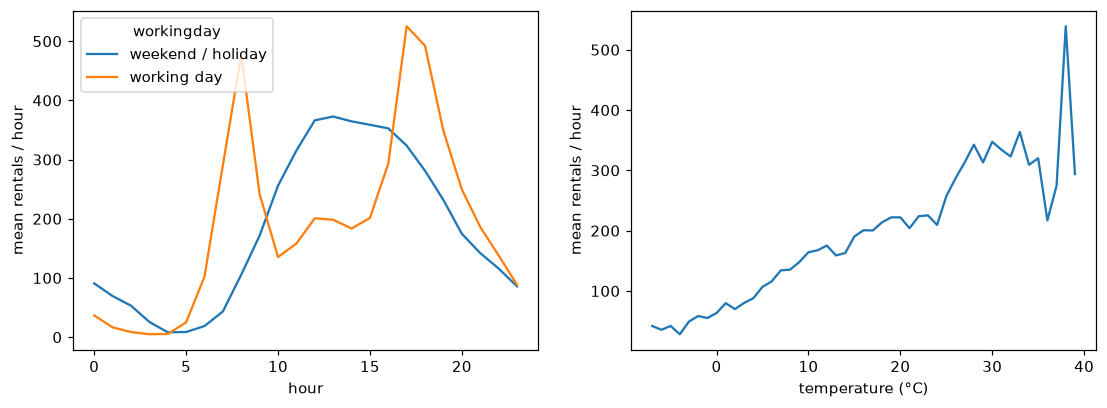

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df.pivot_table(TARGET, "hr", "workingday").rename(
    columns={0: "weekend / holiday", 1: "working day"}
).plot(ax=axes[0], xlabel="hour", ylabel="mean rentals / hour")
df.groupby(df.temp.round())[TARGET].mean().plot(
    ax=axes[1], xlabel="temperature (°C)", ylabel="mean rentals / hour"
)
fig.savefig(FIG / "eda.png")

In [3]:
X.corr("spearman").round(2)

,hr,weekday,workingday,holiday,season,mnth,yr,weathersit,temp,hum,windspeed
hr,1.00,-0.00,0.00,0.00,-0.01,-0.01,-0.00,-0.03,0.13,-0.28,0.14
weekday,-0.00,1.00,0.04,-0.10,-0.00,0.01,-0.00,0.00,-0.01,-0.04,0.01
workingday,0.00,0.04,1.00,-0.25,0.01,-0.00,-0.00,0.04,0.05,0.02,-0.01
holiday,0.00,-0.10,-0.25,1.00,-0.01,0.02,0.01,-0.01,-0.03,-0.01,0.00
season,-0.01,-0.00,0.01,-0.01,1.00,0.83,-0.01,-0.01,0.31,0.15,-0.14
mnth,-0.01,0.01,-0.00,0.02,0.83,1.00,-0.01,0.01,0.19,0.16,-0.13
yr,-0.00,-0.00,-0.00,0.01,-0.01,-0.01,1.00,-0.01,0.04,-0.08,-0.01
weathersit,-0.03,0.00,0.04,-0.01,-0.01,0.01,-0.01,1.00,-0.10,0.41,0.01
temp,0.13,-0.01,0.05,-0.03,0.31,0.19,0.04,-0.10,1.00,-0.06,-0.01
hum,-0.28,-0.04,0.02,-0.01,0.15,0.16,-0.08,0.41,-0.06,1.00,-0.29


## Global explanation

In [4]:
explainer = shap.TreeExplainer(model)
sv = explainer(X)
S = pd.DataFrame(sv.values, columns=FEATURES, index=X.index)

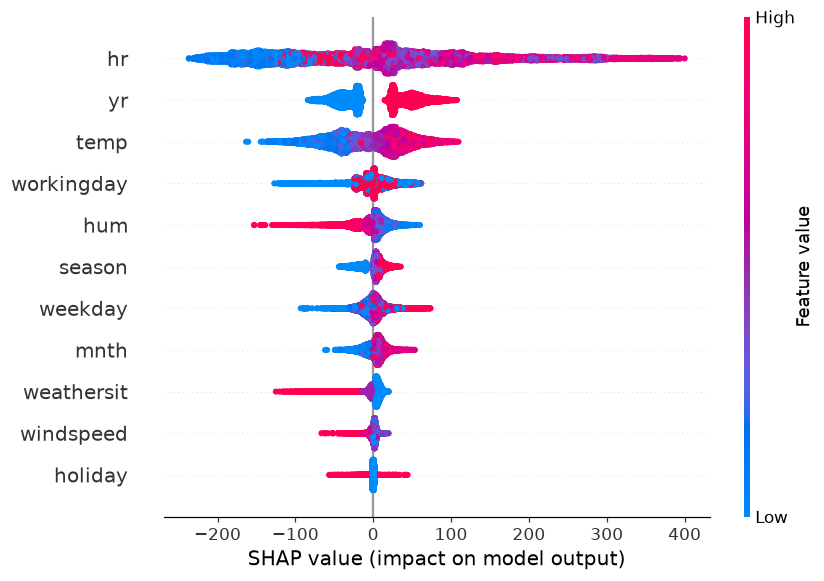

In [5]:
shap.plots.beeswarm(sv, max_display=len(FEATURES), show=False)
plt.savefig(FIG / "beeswarm.png")
plt.show()

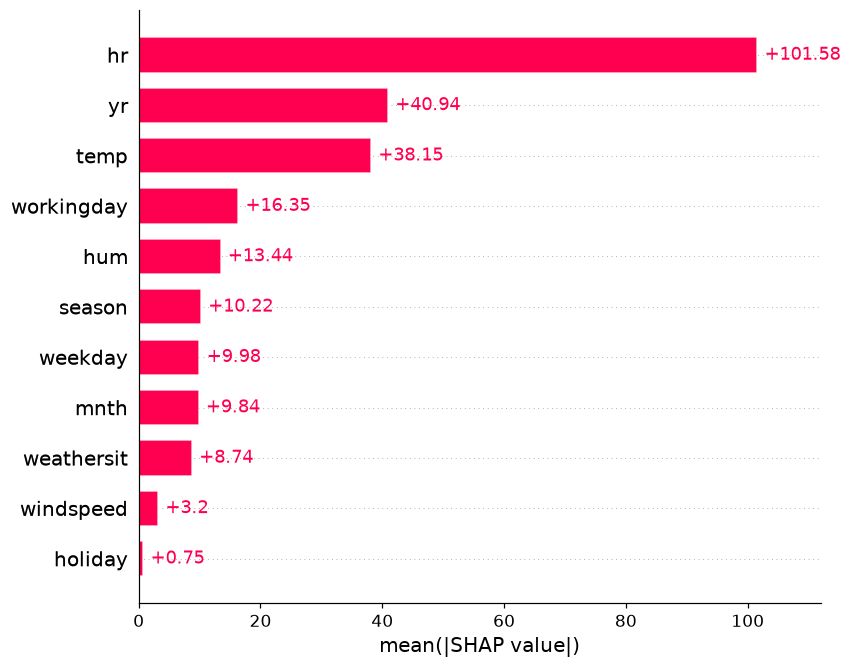

In [6]:
shap.plots.bar(sv, max_display=len(FEATURES), show=False)
plt.savefig(FIG / "importance.png")
plt.show()

## Dependence and interactions: does warmth matter only during the day?

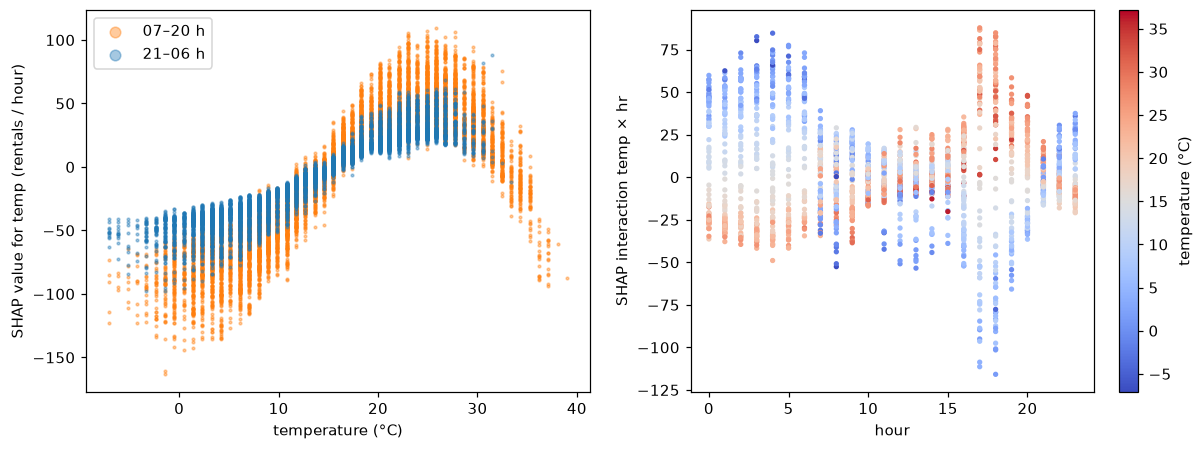

In [7]:
day = X.hr.between(7, 20)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for mask, label, c in [(day, "07–20 h", "tab:orange"), (~day, "21–06 h", "tab:blue")]:
    axes[0].scatter(X.temp[mask], S.temp[mask], s=3, alpha=0.4, c=c, label=label)
axes[0].set(xlabel="temperature (°C)", ylabel="SHAP value for temp (rentals / hour)")
axes[0].legend(markerscale=4)

sample = X.sample(2000, random_state=0)
inter = explainer.shap_interaction_values(sample)
i, j = FEATURES.index("temp"), FEATURES.index("hr")
pts = axes[1].scatter(sample.hr, 2 * inter[:, i, j], c=sample.temp, cmap="coolwarm", s=6)
axes[1].set(xlabel="hour", ylabel="SHAP interaction temp × hr")
fig.colorbar(pts, ax=axes[1], label="temperature (°C)")
fig.savefig(FIG / "dependence_temp_hr.png")

In [8]:
mean_inter = pd.DataFrame(np.abs(inter).mean(0), FEATURES, FEATURES)
pairs = mean_inter.where(np.triu(np.ones_like(mean_inter, bool), 1)).stack()
(2 * pairs).sort_values(ascending=False).head(8).round(1)

hr  workingday    32.9
    temp          22.8
    yr            22.8
    weekday       17.7
    hum           10.0
yr  temp           7.4
hr  season         5.7
    weathersit     5.6
dtype: float64

## Local explanation: peak hour vs. rainy Sunday

peak: Wed 2012-09-12 18:00 977 903


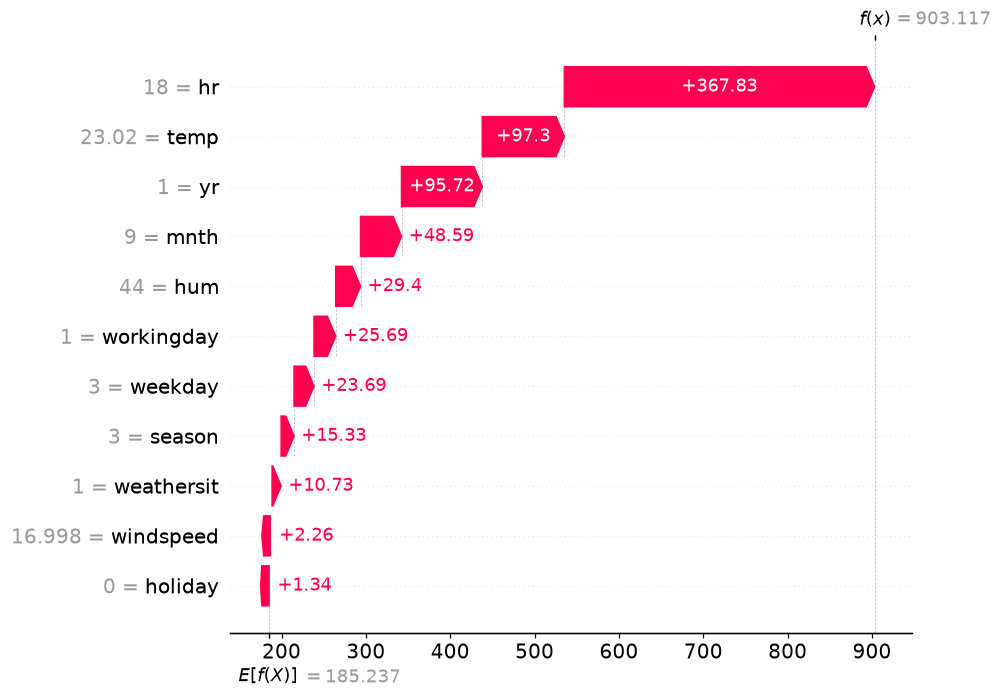

rainy_sunday: Sun 2011-01-02 14:00 59 73


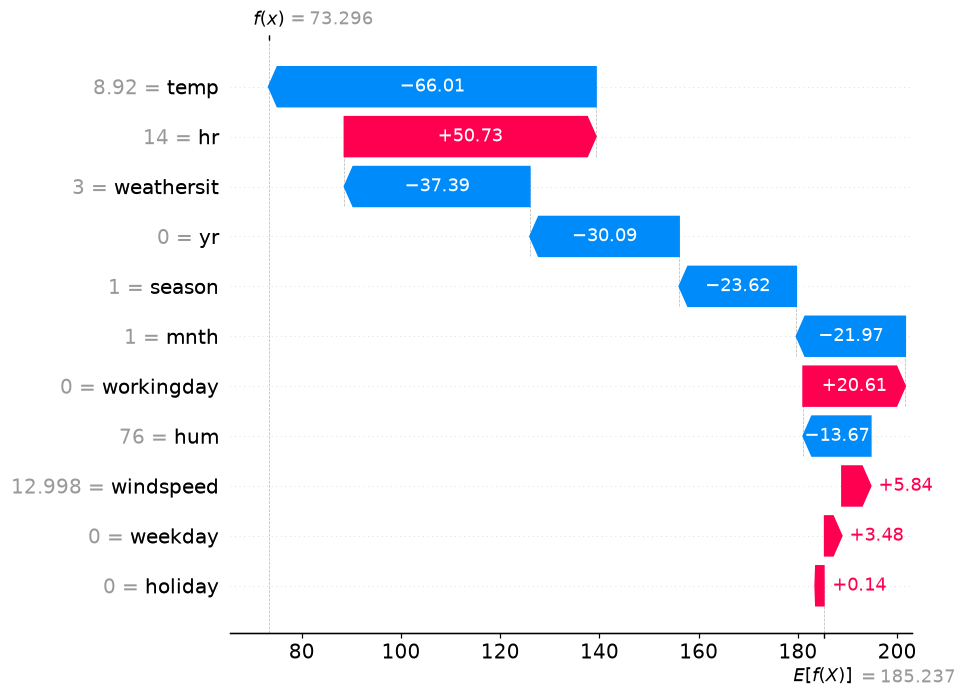

In [9]:
pred = model.predict(X)
cases = {
    "peak": df[TARGET].idxmax(),
    "rainy_sunday": df[
        (df.weekday == 0) & (df.weathersit >= 3) & df.hr.between(10, 17)
    ].temp.idxmax(),
}
for name, idx in cases.items():
    r = df.loc[idx]
    print(f"{name}: {r.dteday:%a %Y-%m-%d} {r.hr:02d}:00", r[TARGET], round(pred[idx]))
    shap.plots.waterfall(sv[idx], max_display=12, show=False)
    plt.savefig(FIG / f"waterfall_{name}.png")
    plt.show()

## SHAP vs. permutation importance vs. partial dependence

In [10]:
def rmse(p):
    return np.sqrt(np.mean((yt - p) ** 2))


base = rmse(model.predict(Xt))
rng = np.random.default_rng(0)
pi = pd.Series(
    {
        f: np.mean(
            [
                rmse(model.predict(Xt.assign(**{f: rng.permutation(Xt[f].to_numpy())}))) - base
                for _ in range(5)
            ]
        )
        for f in FEATURES
    }
)
cmp = pd.DataFrame({"mean |SHAP| (test)": S.loc[test.index].abs().mean(), "permutation ΔRMSE": pi})
cmp = cmp.sort_values("mean |SHAP| (test)")
cmp.div(cmp.max()).plot.barh(figsize=(7, 5), xlabel="relative importance")
plt.savefig(FIG / "shap_vs_permutation.png")
cmp.round(1).iloc[::-1]

,mean |SHAP| (test),permutation ΔRMSE
hr,109.7,176.8
yr,44.8,0.0
temp,42.4,40.0
workingday,18.5,42.6
season,13.8,7.9
hum,13.5,9.5
mnth,11.3,2.4
weathersit,10.9,7.4
weekday,10.5,16.3
windspeed,2.6,1.1


In [11]:
def pdp(f, grid, base):
    rep = base.loc[base.index.repeat(len(grid))].assign(**{f: np.tile(grid, len(base))})
    return model.predict(rep).reshape(len(base), -1).mean(0)


bg = X.sample(2000, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, f, grid in [
    (axes[0], "temp", np.linspace(X.temp.min(), X.temp.max(), 48)),
    (axes[1], "hr", np.arange(24)),
]:
    ax.scatter(X[f], S[f], s=2, alpha=0.15, c="gray", label="SHAP (per row)")
    ax.plot(grid, pdp(f, grid, bg) - pred.mean(), c="tab:red", lw=2, label="PDP (centered)")
    ax.set(xlabel=f, ylabel="effect on rentals / hour")
    ax.legend(markerscale=5)
fig.savefig(FIG / "shap_vs_pdp.png")

## What if it were 5 °C warmer?

In [12]:
delta = model.predict(X.assign(temp=X.temp + 5)) - pred
effect = df.assign(delta=delta).pivot_table("delta", "hr", "season").rename(columns=SEASONS)
ax = effect.plot(figsize=(8, 4.5), xlabel="hour", ylabel="Δ predicted rentals / hour")
ax.axhline(0, c="k", lw=0.8)
plt.savefig(FIG / "whatif_plus5.png")
df.assign(delta=delta).groupby("season").delta.mean().rename(SEASONS).round(1)

season
winter    22.2
spring     4.2
summer   -23.0
fall      21.7
Name: delta, dtype: float64